<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS11/JS11_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tugas Lab JS11 – Convolutional Neural Network (CNN)
Tugas ini memiliki dua bagian yang harus dikerjakan secara berurutan:
1. Modifikasi model CNN pada Praktikum 2 hingga memperoleh akurasi testing lebih dari 80%.
2. Membuat model CNN untuk klasifikasi dataset MNIST.

## Tugas 1 — Modifikasi CNN Praktikum 2
###Langkah 1 - Load Library

In [1]:
#Langkah 1 — Load library
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: []


### Langkah 2 - Load Dataset CIFAR-10

Dataset CIFAR-10 terdiri dari 60.000 citra berwarna berukuran 32 × 32 piksel dengan 10 kelas objek.

Dataset dibagi menjadi 50.000 data training dan 10.000 data testing.

In [2]:

# Load CIFAR-10
(train_images, train_labels), (test_images, test_labels) = (
    datasets.cifar10.load_data()
)

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("Training:", train_images.shape)
print("Training labels:", train_labels.shape)
print("Testing:", test_images.shape)
print("Testing labels:", test_labels.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Training: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing: (10000, 32, 32, 3)
Testing labels: (10000, 1)


###Langkah 3 — Preprocessing data

In [3]:
# Normalisasi piksel
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

# Memisahkan 5.000 data untuk validation
X_val = train_images[-5000:]
y_val = train_labels[-5000:]

X_train = train_images[:-5000]
y_train = train_labels[:-5000]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", test_images.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


###Langkah 4 — Verifikasi data

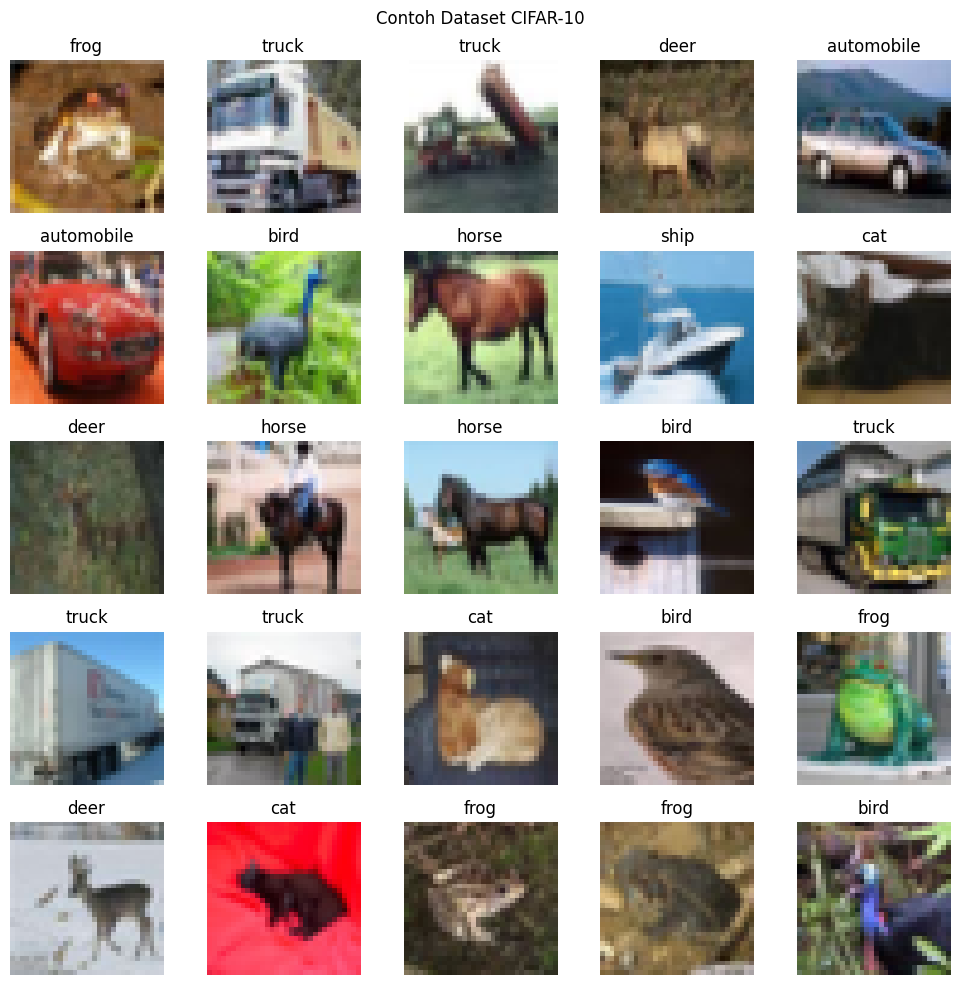

In [4]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.suptitle("Contoh Dataset CIFAR-10")
plt.tight_layout()
plt.show()

###Langkah 5 — Model CNN awal

In [5]:
def build_baseline_cnn():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10)
    ])

    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    return model


baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
baseline_model = build_baseline_cnn()

start = time.time()

baseline_history = baseline_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

baseline_time = time.time() - start

print("Waktu training:", round(baseline_time, 2), "detik")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 56s 77ms/step - accuracy: 0.3952 - loss: 1.6415 - val_accuracy: 0.5028 - val_loss: 1.3716
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 52s 74ms/step - accuracy: 0.5418 - loss: 1.2816 - val_accuracy: 0.5822 - val_loss: 1.1888
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 52s 74ms/step - accuracy: 0.5970 - loss: 1.1422 - val_accuracy: 0.6202 - val_loss: 1.0809
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 73ms/step - accuracy: 0.6324 - loss: 1.0418 - val_accuracy: 0.6336 - val_loss: 1.0302
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - accuracy: 0.6645 - loss: 0.9611 - val_accuracy: 0.6592 - val_loss: 0.9730
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 80s 73ms/step - accuracy: 0.6877 - loss: 0.8963 - val_accuracy: 0.6708 - val_loss: 0.9374
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.7072 - loss: 0.8393 - val_accuracy: 0.6910 - val_loss: 0.9017
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 75ms/step - accuracy: 0.7232 - loss: 0.7938 - 

In [7]:
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(
    test_images,
    test_labels,
    verbose=2
)

print("Baseline Test Accuracy:", baseline_test_acc)
print("Baseline Test Loss:", baseline_test_loss)

313/313 - 3s - 10ms/step - accuracy: 0.6940 - loss: 0.8974
Baseline Test Accuracy: 0.6940000057220459
Baseline Test Loss: 0.897388756275177


###Langkah 6 — Modifikasi model CNN

In [8]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")

In [9]:
def build_improved_cnn():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),

        data_augmentation,

        # Blok konvolusi 1
        layers.Conv2D(
            32, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        # Blok konvolusi 2
        layers.Conv2D(
            64, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        # Blok konvolusi 3
        layers.Conv2D(
            128, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128, (3, 3), padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        # Klasifikasi
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    return model


improved_model = build_improved_cnn()
improved_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

###Langkah 7 — Training model modifikasi

In [10]:
early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=8,
    restore_best_weights=True,
    mode="max"
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

start = time.time()

improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=60,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

improved_time = time.time() - start

print("Waktu training:", round(improved_time, 2), "detik")

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 370s 520ms/step - accuracy: 0.4162 - loss: 1.5970 - val_accuracy: 0.4282 - val_loss: 1.6197 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 367s 521ms/step - accuracy: 0.5332 - loss: 1.2998 - val_accuracy: 0.4278 - val_loss: 1.9432 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 383s 521ms/step - accuracy: 0.5828 - loss: 1.1746 - val_accuracy: 0.4514 - val_loss: 1.8415 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 368s 523ms/step - accuracy: 0.6173 - loss: 1.0825 - val_accuracy: 0.5528 - val_loss: 1.4058 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 382s 524ms/step - accuracy: 0.6445 - loss: 1.0162 - val_accuracy: 0.5498 - val_loss: 1.5001 - learning_rate: 0.0010
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 373s 529ms/step - accuracy: 0.6690 - loss: 0.9513 - val_accuracy: 0.6354 - val_loss: 1.1285 - learning_rate: 0.0010
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 366s 520ms/step - accura

###Langkah 8 — Evaluasi model modifikasi

In [11]:
improved_test_loss, improved_test_acc = improved_model.evaluate(
    test_images,
    test_labels,
    verbose=2
)

print("Improved Test Accuracy:", improved_test_acc)
print("Improved Test Loss:", improved_test_loss)
print("Improved Test Accuracy (%):", improved_test_acc * 100)

if improved_test_acc > 0.80:
    print("Target akurasi testing > 80% tercapai.")
else:
    print("Target belum tercapai. Training perlu dilanjutkan atau konfigurasi diperbaiki.")

313/313 - 18s - 59ms/step - accuracy: 0.8225 - loss: 0.5292
Improved Test Accuracy: 0.8224999904632568
Improved Test Loss: 0.5292122960090637
Improved Test Accuracy (%): 82.24999904632568
Target akurasi testing > 80% tercapai.


###Langkah 9 — Perbandingan hasil

In [12]:
comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Test Accuracy": [
        baseline_test_acc,
        improved_test_acc
    ],
    "Test Loss": [
        baseline_test_loss,
        improved_test_loss
    ],
    "Training Time (s)": [
        baseline_time,
        improved_time
    ]
})

display(comparison)

,Model,Test Accuracy,Test Loss,Training Time (s)
0,Baseline CNN,0.6940,0.897389,645.015909
1,Improved CNN,0.8225,0.529212,16750.389656


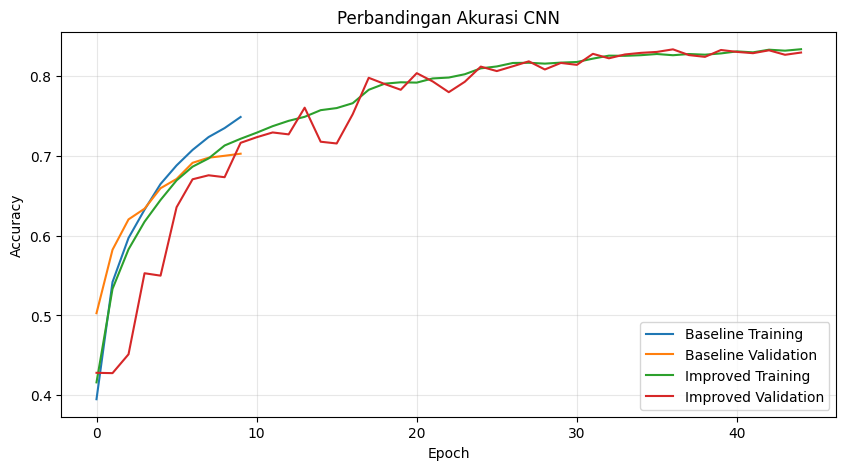

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_history.history["accuracy"],
    label="Baseline Training"
)
plt.plot(
    baseline_history.history["val_accuracy"],
    label="Baseline Validation"
)
plt.plot(
    improved_history.history["accuracy"],
    label="Improved Training"
)
plt.plot(
    improved_history.history["val_accuracy"],
    label="Improved Validation"
)

plt.title("Perbandingan Akurasi CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

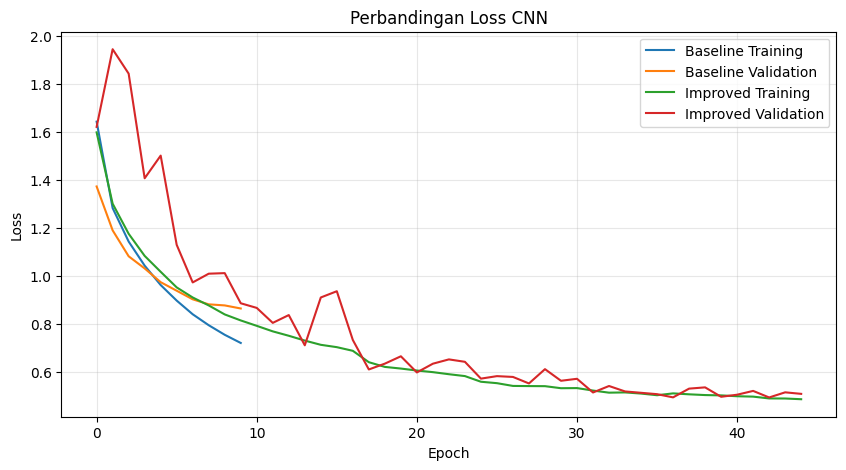

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Baseline Training"
)
plt.plot(
    baseline_history.history["val_loss"],
    label="Baseline Validation"
)
plt.plot(
    improved_history.history["loss"],
    label="Improved Training"
)
plt.plot(
    improved_history.history["val_loss"],
    label="Improved Validation"
)

plt.title("Perbandingan Loss CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

###Langkah 10 — Confusion matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step


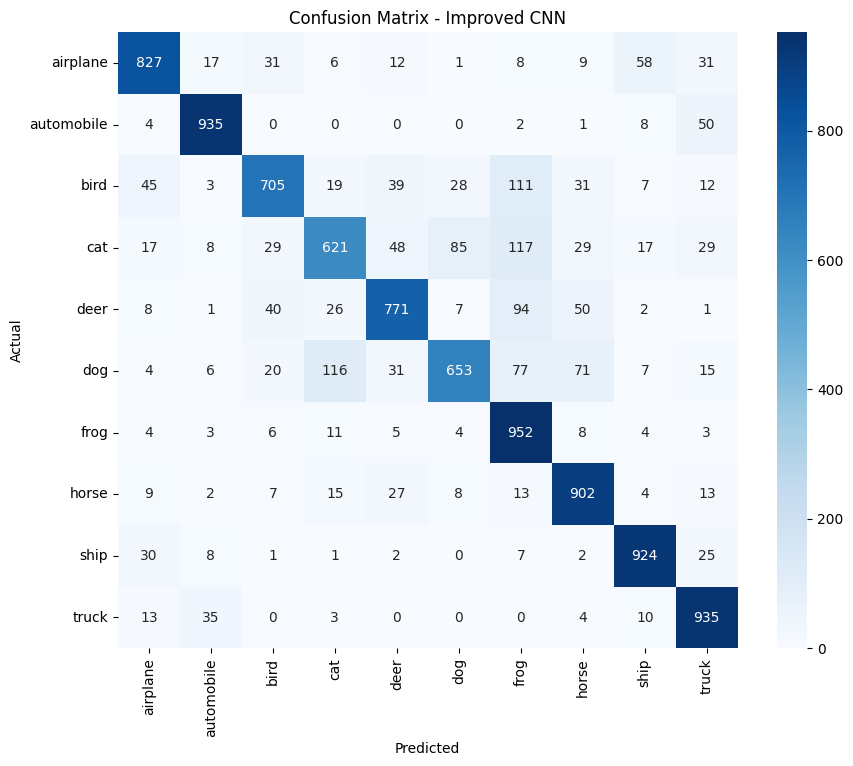

              precision    recall  f1-score   support

    airplane     0.8606    0.8270    0.8434      1000
  automobile     0.9185    0.9350    0.9267      1000
        bird     0.8403    0.7050    0.7667      1000
         cat     0.7592    0.6210    0.6832      1000
        deer     0.8246    0.7710    0.7969      1000
         dog     0.8308    0.6530    0.7312      1000
        frog     0.6894    0.9520    0.7997      1000
       horse     0.8148    0.9020    0.8562      1000
        ship     0.8876    0.9240    0.9054      1000
       truck     0.8393    0.9350    0.8846      1000

    accuracy                         0.8225     10000
   macro avg     0.8265    0.8225    0.8194     10000
weighted avg     0.8265    0.8225    0.8194     10000



In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_logits = improved_model.predict(test_images)
test_predictions = np.argmax(test_logits, axis=1)

cm = confusion_matrix(
    test_labels.flatten(),
    test_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Improved CNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(
    test_labels.flatten(),
    test_predictions,
    target_names=class_names,
    digits=4
))

##Tugas 2 — Membuat model CNN untuk MNIST
###Langkah 1 — Import library

In [16]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import seaborn as sns

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


###Langkah 2 — Load dataset MNIST

In [17]:
# Load dataset MNIST
(X_train_original, y_train_original), (X_test_original, y_test) = (
    datasets.mnist.load_data()
)

print("Training:", X_train_original.shape)
print("Training labels:", y_train_original.shape)
print("Testing:", X_test_original.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (60000, 28, 28)
Training labels: (60000,)
Testing: (10000, 28, 28)
Testing labels: (10000,)


###Langkah 3 — Verifikasi dataset

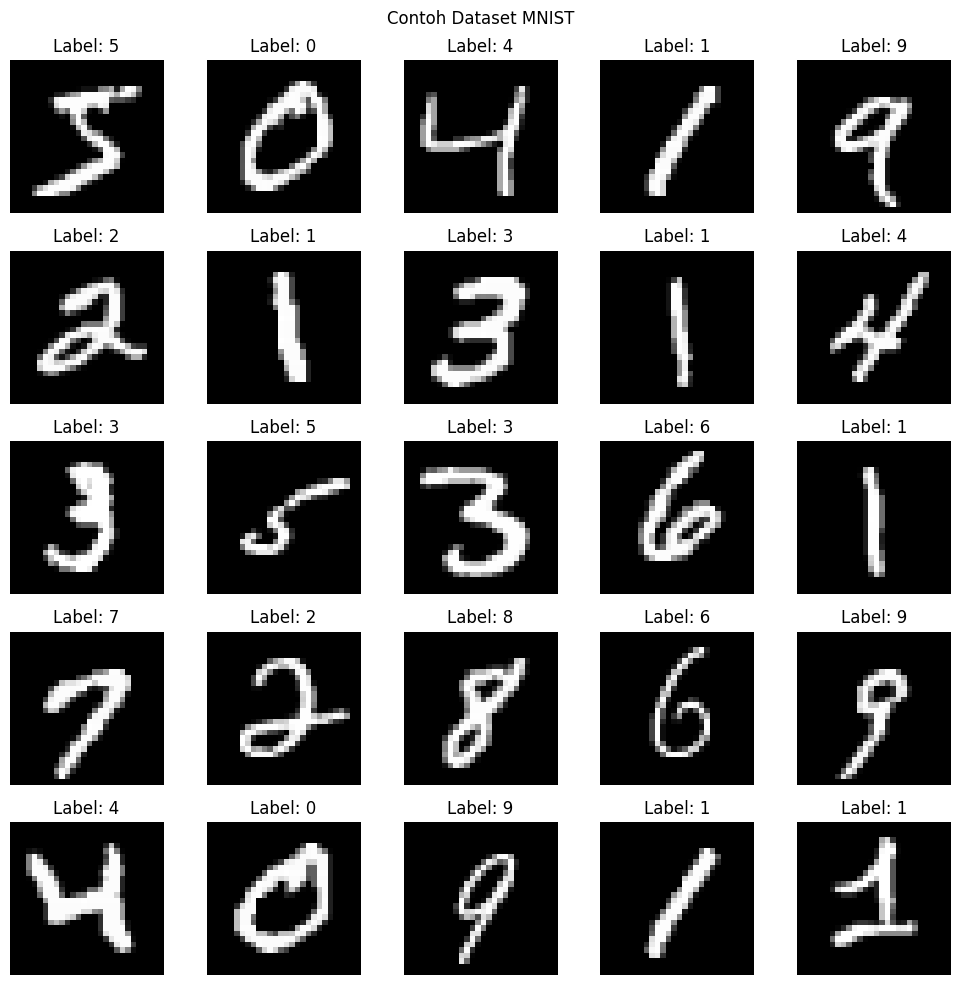

In [18]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_original[i], cmap="gray")
    plt.title(f"Label: {y_train_original[i]}")
    plt.axis("off")

plt.suptitle("Contoh Dataset MNIST")
plt.tight_layout()
plt.show()

###Langkah 4 — Preprocessing data

In [19]:
# Normalisasi nilai piksel dari 0-255 menjadi 0-1
X_train = X_train_original.astype("float32") / 255.0
X_test = X_test_original.astype("float32") / 255.0

# Menambahkan channel grayscale
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

# Membagi training menjadi 55.000 training dan 5.000 validation
X_val = X_train[-5000:]
y_val = y_train_original[-5000:]

X_train = X_train[:-5000]
y_train = y_train_original[:-5000]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (55000, 28, 28, 1)
Validation: (5000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


###Langkah 5 — Membuat model CNN

In [20]:
mnist_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Blok konvolusi pertama
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Blok konvolusi kedua
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Fully connected block
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output 10 kelas angka
    layers.Dense(10, activation="softmax")
])

mnist_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

###Langkah 6 — Compile model

In [21]:
mnist_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model berhasil di-compile.")

Model berhasil di-compile.


###Langkah 7 — Training model

In [22]:
early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    restore_best_weights=True,
    mode="max"
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

start = time.time()

mnist_history = mnist_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

mnist_training_time = time.time() - start

print("Waktu training:", round(mnist_training_time, 2), "detik")

Epoch 1/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - accuracy: 0.9256 - loss: 0.2425 - val_accuracy: 0.9848 - val_loss: 0.0553 - learning_rate: 0.0010
Epoch 2/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 55s 129ms/step - accuracy: 0.9791 - loss: 0.0696 - val_accuracy: 0.9876 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 3/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 55s 127ms/step - accuracy: 0.9842 - loss: 0.0488 - val_accuracy: 0.9894 - val_loss: 0.0363 - learning_rate: 0.0010
Epoch 4/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 82s 128ms/step - accuracy: 0.9883 - loss: 0.0380 - val_accuracy: 0.9908 - val_loss: 0.0340 - learning_rate: 0.0010
Epoch 5/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 85s 135ms/step - accuracy: 0.9894 - loss: 0.0326 - val_accuracy: 0.9914 - val_loss: 0.0329 - learning_rate: 0.0010
Epoch 6/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 55s 127ms/step - accuracy: 0.9913 - loss: 0.0260 - val_accuracy: 0.9920 - val_loss: 0.0336 - learning_rate: 0.0010
Epoch 7/20
430/430 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.99

###Langkah 8 — Evaluasi model

In [23]:
mnist_test_loss, mnist_test_acc = mnist_model.evaluate(
    X_test,
    y_test,
    verbose=2
)

print("Test Loss:", mnist_test_loss)
print("Test Accuracy:", mnist_test_acc)
print("Test Accuracy (%):", mnist_test_acc * 100)

313/313 - 4s - 13ms/step - accuracy: 0.9919 - loss: 0.0262
Test Loss: 0.026232993230223656
Test Accuracy: 0.9919000267982483
Test Accuracy (%): 99.19000267982483


###Langkah 9 — Grafik akurasi dan loss

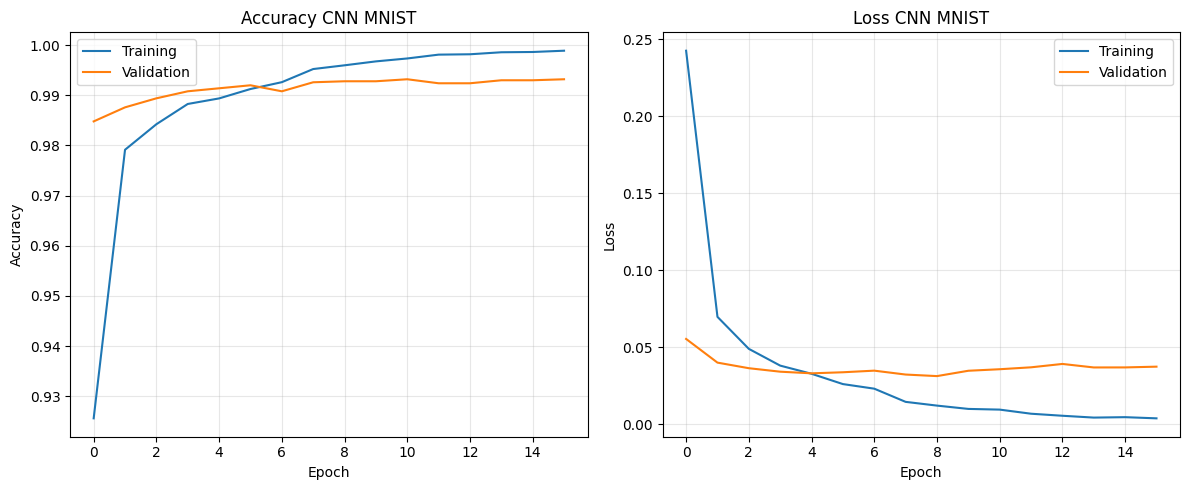

In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mnist_history.history["accuracy"], label="Training")
plt.plot(mnist_history.history["val_accuracy"], label="Validation")
plt.title("Accuracy CNN MNIST")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(mnist_history.history["loss"], label="Training")
plt.plot(mnist_history.history["val_loss"], label="Validation")
plt.title("Loss CNN MNIST")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

###Langkah 10 — Prediksi data testing

In [25]:
# Prediksi data testing
mnist_probabilities = mnist_model.predict(
    X_test,
    verbose=1
)

mnist_predictions = np.argmax(
    mnist_probabilities,
    axis=1
)

print("Contoh label sebenarnya:", y_test[:20])
print("Contoh hasil prediksi:", mnist_predictions[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
Contoh label sebenarnya: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Contoh hasil prediksi: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


###Langkah 11 — Classification report

In [26]:
mnist_accuracy = accuracy_score(
    y_test,
    mnist_predictions
)

mnist_precision = precision_score(
    y_test,
    mnist_predictions,
    average="macro",
    zero_division=0
)

mnist_recall = recall_score(
    y_test,
    mnist_predictions,
    average="macro",
    zero_division=0
)

mnist_f1 = f1_score(
    y_test,
    mnist_predictions,
    average="macro",
    zero_division=0
)

print(classification_report(
    y_test,
    mnist_predictions,
    digits=4,
    zero_division=0
))

mnist_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-Score Macro",
        "Test Loss"
    ],
    "Value": [
        mnist_accuracy,
        mnist_precision,
        mnist_recall,
        mnist_f1,
        mnist_test_loss
    ]
})

display(mnist_metrics)

              precision    recall  f1-score   support

           0     0.9939    0.9969    0.9954       980
           1     0.9947    0.9974    0.9960      1135
           2     0.9913    0.9971    0.9942      1032
           3     0.9853    0.9950    0.9901      1010
           4     0.9939    0.9888    0.9913       982
           5     0.9877    0.9910    0.9894       892
           6     0.9989    0.9823    0.9905       958
           7     0.9961    0.9883    0.9922      1028
           8     0.9878    0.9938    0.9908       974
           9     0.9891    0.9871    0.9881      1009

    accuracy                         0.9919     10000
   macro avg     0.9919    0.9918    0.9918     10000
weighted avg     0.9919    0.9919    0.9919     10000



,Metric,Value
0,Accuracy,0.991900
1,Precision Macro,0.991866
2,Recall Macro,0.991781
3,F1-Score Macro,0.991809
4,Test Loss,0.026233


###Langkah 12 — Confusion matrix

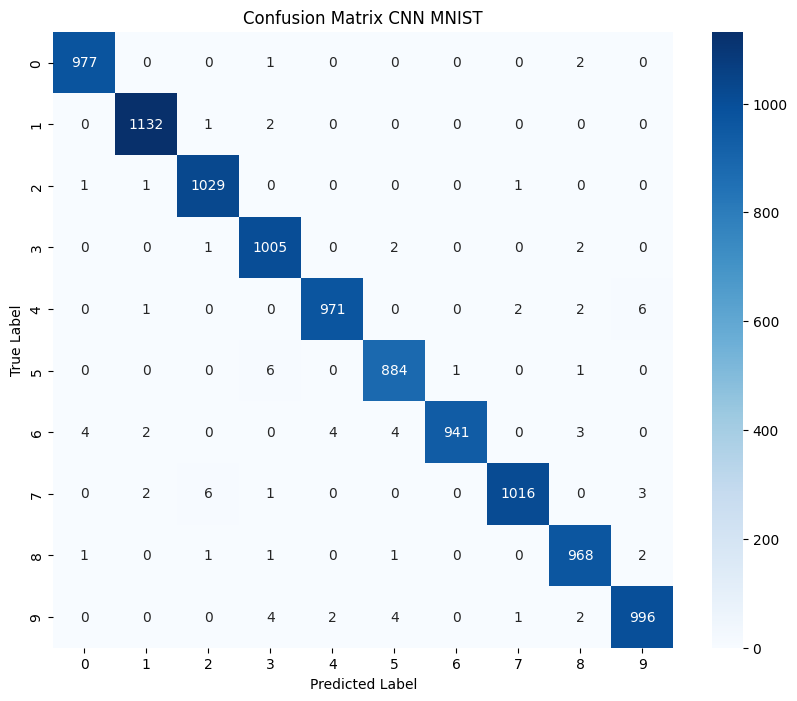

In [27]:
cm = confusion_matrix(
    y_test,
    mnist_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix CNN MNIST")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

###Langkah 13 — Visualisasi hasil prediksi

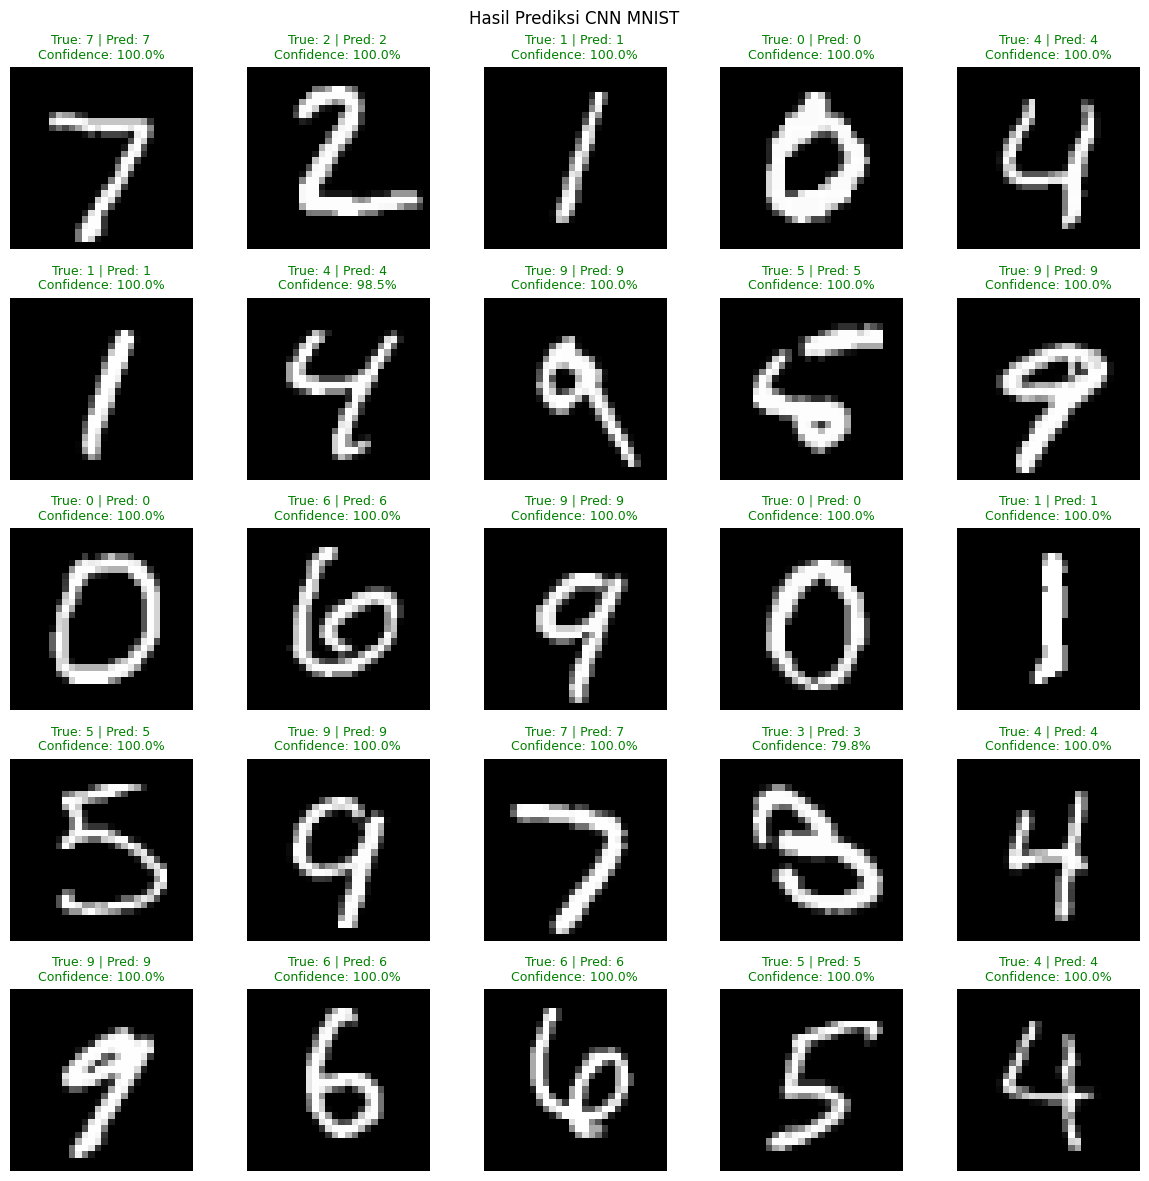

In [28]:
plt.figure(figsize=(12, 12))

for i in range(25):
    plt.subplot(5, 5, i + 1)

    plt.imshow(X_test_original[i], cmap="gray")

    true_label = y_test[i]
    predicted_label = mnist_predictions[i]
    confidence = np.max(mnist_probabilities[i]) * 100

    color = "green" if true_label == predicted_label else "red"

    plt.title(
        f"True: {true_label} | Pred: {predicted_label}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("Hasil Prediksi CNN MNIST")
plt.tight_layout()
plt.show()